# Reto S09 · «Conocer al huésped» · equipo «Las Palmeras» (entrega de referencia)

**Qué hace este cuaderno:** segmenta a los 1.200 huéspedes de TurisData (k-means con `k` elegido por silueta y por negocio), dibuja el mapa en 2D con PCA y construye un recomendador de experiencias comparado con la popularidad.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo*. La primera celda descarga los datos del repositorio del curso. Semilla fija: `SEMILLA = 42`. Debe salir `k = 4`, los tamaños de la ficha y la misma tabla de RMSE y precision@3.

**Uso de la IA (declarado):** la usamos para (1) entender qué mide la silueta, (2) proponer nombres de segmento y (3) revisar la redacción de la ficha. Comprobamos a mano que cada nombre cuadra con **dos cifras** del perfil, que las cifras de la ficha son las de este cuaderno y que `recomendar` no devuelve nada ya valorado. Cambiamos dos nombres que la IA sugirió («Viajeros senior», «Nómadas») porque no se apoyaban en las cifras. No pegamos datos personales ni claves en ninguna IA.

## 1. Preparar el cuaderno y los datos

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")

huespedes = pd.read_csv(dato("huespedes.csv"))
print(huespedes.shape)
huespedes.head()

(1200, 8)


,id_huesped,edad,gasto_medio_dia,noches_medias,reservas_anio,antelacion_media,pct_gasto_actividades,viaja_con_ninos
0,1,26,92.25,3.9,4,24,40.2,0
1,2,41,92.81,5.3,2,115,17.6,1
2,3,60,200.24,6.4,1,126,39.0,0
3,4,38,74.47,5.5,0,58,86.7,0
4,5,54,266.46,6.9,1,116,11.7,0


In [3]:
huespedes.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
id_huesped,1200.0,600.5,346.6,1.0,300.8,600.5,900.2,1200.0
edad,1200.0,41.2,12.1,18.0,33.0,39.0,50.0,75.0
gasto_medio_dia,1200.0,124.2,60.9,34.6,79.6,101.8,155.1,338.7
noches_medias,1200.0,6.5,2.3,1.0,5.4,6.9,8.1,11.5
reservas_anio,1200.0,2.0,1.7,0.0,1.0,2.0,3.0,10.0
antelacion_media,1200.0,78.7,36.5,0.0,53.0,83.0,106.0,180.0
pct_gasto_actividades,1200.0,38.5,23.7,0.0,20.9,31.7,53.2,100.0
viaja_con_ninos,1200.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0


`id_huesped` es solo un identificador y no entra en la segmentación. Las demás siete variables tienen escalas muy distintas (edad en decenas, gasto en cientos), así que **se escalan antes de agrupar**: si no, mandaría el gasto.

In [4]:
variables = [c for c in huespedes.columns if c != "id_huesped"]
X = StandardScaler().fit_transform(huespedes[variables])
print(X.shape, round(X.mean(), 3), round(X[:, 0].std(), 3))

(1200, 7) 0.0 1.0


## 2. Segmentar y elegir k

In [5]:
siluetas = {}
for k in range(2, 9):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X)
    siluetas[k] = silhouette_score(X, etiquetas)
k_mejor = max(siluetas, key=siluetas.get)
print({k: round(v, 3) for k, v in siluetas.items()})
print("k con mejor silueta:", k_mejor)

{2: 0.367, 3: 0.415, 4: 0.431, 5: 0.414, 6: 0.326, 7: 0.317, 8: 0.257}
k con mejor silueta: 4


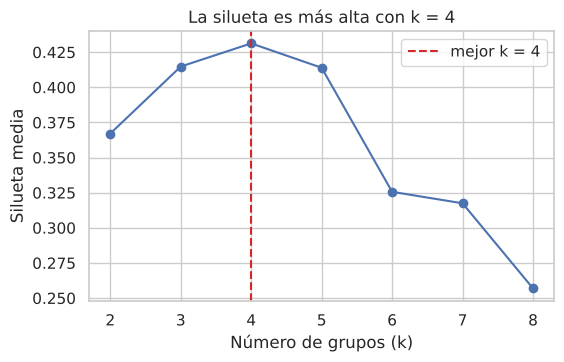

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(siluetas), list(siluetas.values()), marker="o")
ax.axvline(k_mejor, color="tab:red", linestyle="--", label=f"mejor k = {k_mejor}")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silueta media")
ax.set_title(f"La silueta es más alta con k = {k_mejor}")
ax.legend()
plt.show()

La silueta de 3, 4 y 5 casi empata, así que miramos el tamaño de los grupos:

In [7]:
for k in (3, 4, 5):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X)
    print(k, "grupos · tamaños:", np.bincount(etiquetas))

3 grupos · tamaños: [317 480 403]
4 grupos · tamaños: [194 402 317 287]
5 grupos · tamaños: [ 72 402 317 126 283]


**Decisión de `k`.** Elegimos k = 4 porque su silueta es la más alta (0,431), aunque 3 (0,415) y 5 (0,414) casi empatan, y, para el negocio, 4 grupos se pueden gestionar: el más pequeño tiene el 16 % de los huéspedes (con 5 grupos habría uno de solo 72, el 6 %).

## 3. Mapa PCA, perfiles y nombres

In [8]:
k_elegido = 4
km = KMeans(n_clusters=k_elegido, n_init=10, random_state=SEMILLA).fit(X)
huespedes["grupo"] = km.labels_
print(huespedes["grupo"].value_counts().sort_index())

grupo
0    194
1    402
2    317
3    287
Name: count, dtype: int64


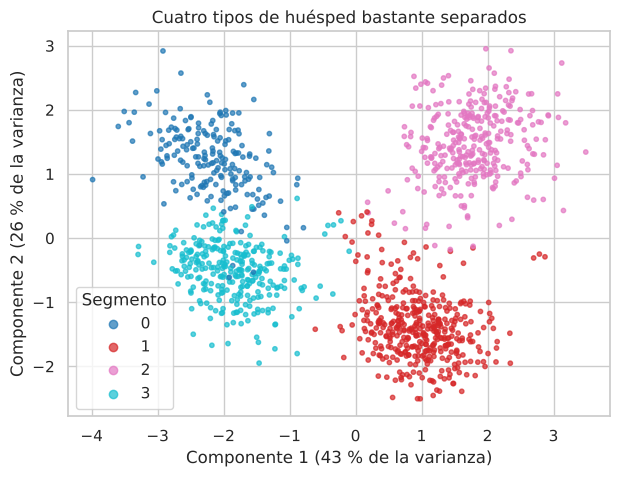

Información conservada con 2 componentes: 68.7 %


In [9]:
pca = PCA(n_components=2, random_state=SEMILLA)
Z2 = pca.fit_transform(X)
var1, var2 = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(7, 5))
dibujo = ax.scatter(Z2[:, 0], Z2[:, 1], c=huespedes["grupo"], cmap="tab10", s=10, alpha=0.7)
ax.set_title("Cuatro tipos de huésped bastante separados")
ax.set_xlabel(f"Componente 1 ({var1:.0f} % de la varianza)")
ax.set_ylabel(f"Componente 2 ({var2:.0f} % de la varianza)")
ax.legend(*dibujo.legend_elements(), title="Segmento")
fig.savefig("mapa_pca.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Información conservada con 2 componentes: {var1 + var2:.1f} %")

Con 2 componentes se conserva el 68,7 % de la información (43 % + 26 %): el mapa es una buena foto, aunque no lo recoge todo.

In [10]:
perfil = huespedes.groupby("grupo")[variables].mean().round(1)
perfil["n_huespedes"] = huespedes["grupo"].value_counts().sort_index()
perfil["pct"] = (perfil["n_huespedes"] / len(huespedes) * 100).round(0)
perfil

,edad,gasto_medio_dia,noches_medias,reservas_anio,antelacion_media,pct_gasto_actividades,viaja_con_ninos,n_huespedes,pct
grupo,,,,,,,,,
0,34.6,120.4,2.6,4.0,22.2,41.2,0.1,194,16.0
1,40.3,95.2,7.4,1.3,110.3,26.0,0.9,402,34.0
2,57.2,211.4,8.1,1.6,90.3,20.0,0.0,317,26.0
3,29.3,71.2,6.1,2.1,59.7,74.6,0.0,287,24.0


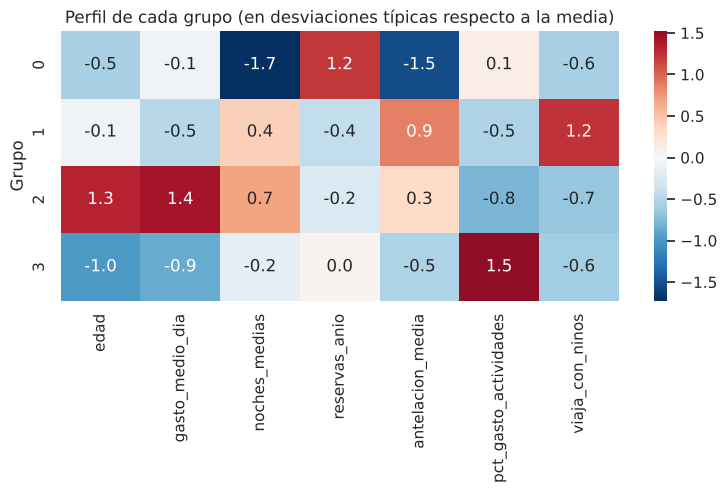

In [11]:
perfil_z = pd.DataFrame(km.cluster_centers_, columns=variables)
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(perfil_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Perfil de cada grupo (en desviaciones típicas respecto a la media)")
ax.set_ylabel("Grupo")
plt.show()

**Los números de grupo los pone el algoritmo;** los nombres se han puesto mirando **nuestro** `perfil`, no copiando de otro sitio.

In [12]:
nombres_segmentos = {0: "Escapadas frecuentes", 1: "Familias de larga estancia",
                     2: "Mayores de alto gasto", 3: "Jóvenes aventureros"}
perfil["nombre"] = pd.Series(nombres_segmentos)
print(perfil[["nombre", "n_huespedes", "pct"]])
print("Suma de tamaños:", perfil["n_huespedes"].sum())

                           nombre  n_huespedes   pct
grupo                                               
0            Escapadas frecuentes          194  16.0
1      Familias de larga estancia          402  34.0
2           Mayores de alto gasto          317  26.0
3             Jóvenes aventureros          287  24.0
Suma de tamaños: 1200


## 4. Recomendador de experiencias

In [13]:
from sklearn.metrics.pairwise import cosine_similarity

valoraciones = pd.read_csv(dato("valoraciones_experiencias.csv"))
experiencias = pd.read_csv(dato("experiencias.csv"))

prueba = valoraciones.sample(frac=0.2, random_state=SEMILLA)
entrenamiento = valoraciones.drop(prueba.index)

R = entrenamiento.pivot(index="id_usuario", columns="id_experiencia", values="valoracion")
R = R.reindex(index=range(1, 301), columns=range(1, 26))
M = R.notna().values
media_global = entrenamiento["valoracion"].mean()
print(valoraciones.shape, experiencias.shape, len(entrenamiento), len(prueba))
print("Matriz:", R.shape, "· casillas con dato:", f"{M.mean():.0%}")

(2232, 3) (25, 4) 1786 446
Matriz: (300, 25) · casillas con dato: 24%


In [14]:
fila_p = prueba["id_usuario"].values - 1
col_p = prueba["id_experiencia"].values - 1
real_p = prueba["valoracion"].values

def evaluar_rmse(P):
    pred = np.clip(P[fila_p, col_p], 1, 5)
    return float(np.sqrt(np.mean((pred - real_p) ** 2)))

relevantes = prueba[prueba["valoracion"] >= 4]

def precision_k(P, k=3):
    aciertos = []
    for u, g in relevantes.groupby("id_usuario"):
        puntuacion = P[u - 1].astype(float).copy()
        puntuacion[M[u - 1]] = -np.inf
        recomendadas = np.argsort(-puntuacion)[:k] + 1
        aciertos.append(len(set(recomendadas) & set(g["id_experiencia"])) / k)
    return float(np.mean(aciertos))

print("Usuarios evaluables:", relevantes["id_usuario"].nunique())

Usuarios evaluables: 115


In [15]:
media_item = R.mean()
P_pop = np.tile(media_item.values, (300, 1))
print(f"Popularidad · RMSE = {evaluar_rmse(P_pop):.3f} · precision@3 = {precision_k(P_pop):.3f}")
top = media_item.sort_values(ascending=False).head(5)
print(experiencias.set_index("id_experiencia").loc[top.index, "nombre"].to_frame().assign(nota=top.round(2)))

Popularidad · RMSE = 1.029 · precision@3 = 0.125
                                 nombre  nota
id_experiencia                               
11                     Parque Timanfaya  4.43
22                   Visita a Garachico  4.21
2               Observación de cetáceos  3.93
24                            Parapente  3.82
13               Astronomía en el Roque  3.77


In [16]:
media_item_v = media_item.fillna(media_global).values
C = np.where(M, R.values - media_item_v[None, :], 0.0)
S = cosine_similarity(C.T)
np.fill_diagonal(S, 0)
P_item = media_item_v[None, :] + (C @ S.T) / (M.astype(float) @ np.abs(S).T + 1e-9)

metodos = {"Popularidad": P_pop, "Item-item": P_item}
tabla = pd.DataFrame({
    "RMSE": {n: evaluar_rmse(P) for n, P in metodos.items()},
    "precision@3": {n: precision_k(P) for n, P in metodos.items()},
}).round(3)
tabla

,RMSE,precision@3
Popularidad,1.029,0.125
Item-item,0.895,0.171


**Decisión del método.** Elegimos item-item porque su precision@3 es 0,171 frente a 0,125 de la popularidad y su RMSE es 0,895 frente a 1.029. Con solo 115 usuarios evaluables la prueba es pequeña, pero las diferencias son claras (más de 0,04 en las dos medidas).

In [17]:
def recomendar(id_usuario, n=3, P=P_item):
    puntuacion = P[id_usuario - 1].astype(float).copy()
    puntuacion[M[id_usuario - 1]] = -np.inf
    ids = np.argsort(-puntuacion)[:n] + 1
    res = experiencias.set_index("id_experiencia").loc[ids, ["nombre", "categoria", "isla"]].copy()
    res["nota_prevista"] = np.clip(P[id_usuario - 1][ids - 1], 1, 5).round(2)
    return res

for u in (1, 2, 3):
    print("Usuario", u)
    print(recomendar(u))
    vistas = set(np.where(M[u - 1])[0] + 1)
    print("Recomendadas que ya había valorado:", set(recomendar(u).index) & vistas)

Usuario 1
                          nombre   categoria          isla  nota_prevista
id_experiencia                                                           
11              Parque Timanfaya  naturaleza     Lanzarote           4.73
3                 Ruta por Anaga  naturaleza      Tenerife           4.14
20                Zoo y jardines     familia  Gran Canaria           3.87
Recomendadas que ya había valorado: set()
Usuario 2
                                 nombre categoria      isla  nota_prevista
id_experiencia                                                            
2               Observación de cetáceos       mar  Tenerife           4.55
13               Astronomía en el Roque   cultura  La Palma           4.51
24                            Parapente  aventura  Tenerife           3.90
Recomendadas que ya había valorado: set()
Usuario 3
                                 nombre    categoria           isla  \
id_experiencia                                                        

**Huésped nuevo sin valoraciones (arranque en frío).** No tiene fila en la matriz, así que `recomendar` no sirve. Le enseñaríamos la popularidad: Parque Timanfaya, Visita a Garachico, Observación de cetáceos. En cuanto valore dos o tres experiencias, ya se puede usar item-item.

## 5. Comprobación del riesgo de sesgo de popularidad

In [18]:
todas = [i for u in range(1, 301) for i in recomendar(u, 3).index]
print(len(set(todas)), "experiencias distintas recomendadas, de 25")
print(pd.Series(todas).value_counts().head(3))
todas_pop = [i for u in range(1, 301) for i in recomendar(u, 3, P=P_pop).index]
print(len(set(todas_pop)), "con la popularidad")

18 experiencias distintas recomendadas, de 25
11    160
22    144
24    106
Name: count, dtype: int64


8 con la popularidad


item-item recomienda 18 experiencias distintas de 25 (la popularidad, solo 8), pero Parque Timanfaya sale 160 veces: el sesgo existe, aunque item-item lo reduce. Medida en la ficha: reservar un hueco de cada lista para una experiencia menos conocida.

## Versiones

In [19]:
import sys, sklearn
print("Python", sys.version.split()[0], "· numpy", np.__version__, "· pandas", pd.__version__, "· scikit-learn", sklearn.__version__)

Python 3.13.18 · numpy 2.5.3 · pandas 2.3.3 · scikit-learn 1.9.1
